# Инженерия признаков: прогнозирование покупки на сайте e-commerce

## Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** *Online Shoppers Purchasing Intention*

**Выполнил:** Белозёров Константин Сергеевич  
**Группа:** ПКТб-23-1  
**Преподаватель:** не указан в задании

**Ссылка на репозиторий:** https://github.com/Pankyxa/ML_Spirin  
**Путь к модулю:** `module-4-features/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

*Ноутбук подготовлен с помощью ИИ-ассистента Cursor. Метрики посчитаны на `online_shoppers_intention.csv`.*


## Введение

**Задача.** По сессии на сайте нужно решить, закончится ли она покупкой. Это бинарная классификация: `Revenue = 1` — покупка (15.5% сессий), `0` — ушёл без заказа (84.5%).

**Инженерия признаков** — это перевод сырых счётчиков в величины, которые ближе к решению человека. «Сколько страниц всего», «сколько секунд на страницу», «новичок или вернувшийся» в таблице по отдельности не записаны. Их собирают из соседних столбцов до обучения. Хороший признак можно объяснить менеджеру. Плохой — случайный код браузера, который модель принимает за величину «чем больше номер, тем лучше».

**Зачем это магазину.** Если сессия похожа на покупку, ей можно показать скидку или не мешать. Если сессия холодная, дорогой баннер лучше не тратить. Ошибка стоит по-разному: пропущенная покупка — потерянный заказ, лишняя скидка — отданные деньги тому, кто и так ничего не купил бы.

**Метрика.** Accuracy около 84% получается у модели, которая никогда не предсказывает покупку. Смотреть нужно ROC-AUC и F1. ROC-AUC сравнивает, кто выше в очереди на покупку. F1 не даёт забыть, что покупателей мало.

**Цель работы:**

1. Собрать больше пяти новых признаков из поведения на сайте.
2. Обучить четыре ансамбля и сравнить их.
3. Разобрать лучшую модель через SHAP.


## Теоретическая часть

### Feature Engineering

Сырой лог аналитики — это страницы, секунды и коды. Модель может выучить их и сама, но тогда она тратит деревья на арифметику, которую мы и так знаем: общее число страниц — сумма трёх счётчиков. Явно собранный признак короче и его проще проверить. В интернет-магазине такие признаки ещё и совпадают с языком отчёта: глубина просмотра, отказы, новизна визита, близость к празднику. Если признак нельзя назвать в одном предложении, его лучше не добавлять.

### Категориальные признаки

Label Encoding ставит категориям числа 0, 1, 2. Для «плохо / нормально / отлично» это честно. Для браузера и типа трафика числа ничего не значат: браузер 13 не «больше» браузера 2. One-hot заводит отдельный столбец на каждый код и не создаёт ложную линейку. В этой работе так кодируются тип посетителя, операционная система, браузер, регион и источник трафика. Месяц переводится в номер, потому что у календаря порядок есть.

### Временные признаки

Месяц несёт сезон: ноябрь и декабрь в магазине не равны февралю. Выходной — отдельный бинарный флаг, его нельзя заменить номером дня, если дня в таблице нет. `SpecialDay` уже измеряет близость визита к празднику числом от 0 до 1. Вместе месяц, выходной и `SpecialDay` описывают календарь, а не «ещё один код».

### Признаки из поведения

Сумма страниц говорит, насколько сессия глубокая. Сумма секунд — насколько она длинная. Отношение ценности страницы к числу просмотров отделяет один дорогой товар от долгого бесцельного кликанья. Отношение отказов к выходам сравнивает «сразу ушёл» и «долистал до конца и закрыл». Новичок и вернувшийся покупают по-разному: у новых доля покупок в этих данных выше, около 25% против 14% у вернувшихся.

### Дисбаланс

Покупателей 15.5%. Модель без поправки почти всё записывает в «не купит» и получает высокую accuracy при нулевом recall. `class_weight='balanced'` и `scale_pos_weight` увеличивают цену пропуска покупки. SMOTE синтезирует новых покупателей в пространстве признаков. Здесь выбран вес класса, а не синтетика: исходных сессий достаточно, и не нужно придумывать несуществующие визиты.

### SHAP

SHAP раскладывает конкретный прогноз на вклады признаков. Summary plot — по всей тестовой выборке, waterfall — по одной сессии, dependence — как вклад `PageValues` меняется вместе с самой ценностью страницы.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

| Модель | Как устроена | Зачем здесь |
|--------|--------------|-------------|
| Random Forest | среднее деревьев | базовая устойчивость |
| XGBoost | бустинг по уровням | точный бустинг с регуляризацией |
| LightGBM | бустинг по листьям | быстрый перебор в Optuna |
| CatBoost | бустинг, спокойный к категориям | сравнение с one-hot |


## Описание данных

**Источник:** [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), тот же файл публикуют на [Kaggle](https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention).

- Сессий: 12 330
- Входных признаков: 17, цель `Revenue`
- Числовых: 10
- Категориальных: 7, включая месяц
- Пропусков нет

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Administrative | int | Число административных страниц | 0% |
| ProductRelated | int | Число товарных страниц | 0% |
| ProductRelated_Duration | float | Секунды на товарных страницах | 0% |
| BounceRates | float | Доля отказов | 0% |
| ExitRates | float | Доля выходов | 0% |
| PageValues | float | Средняя ценность страниц перед покупкой | 0% |
| Month | object | Месяц сессии, включая строку `June` | 0% |
| VisitorType | object | New, Returning, Other | 0% |
| Revenue | bool | Цель: была покупка | 0% |

**Классы:** False — 10 422 (84.5%), True — 1 908 (15.5%).

**Файл:** `module-4-features/data/dataset_info.md`


In [1]:
%matplotlib inline

import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import requests
import seaborn as sns
import shap
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/online_shoppers_intention.csv')
print(df.shape)
display(df.head())
print(df['Revenue'].value_counts())
print((df['Revenue'].value_counts(normalize=True) * 100).round(1))


/Users/Pankyxa/projects/ML_Spirin/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64


## Подготовка данных и EDA

Пропусков в файле нет, проверка всё равно печатается. Графики строятся на сырых столбцах, новые признаки собираются следом. Коды браузера и региона не оставляются числами: у них нет порядка.


In [2]:
df.info()
display(df.describe().T.head(12))
print('Пропусков:', int(df.isnull().sum().sum()))
print(df['VisitorType'].value_counts())
print(df['Month'].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


Пропусков: 0
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64


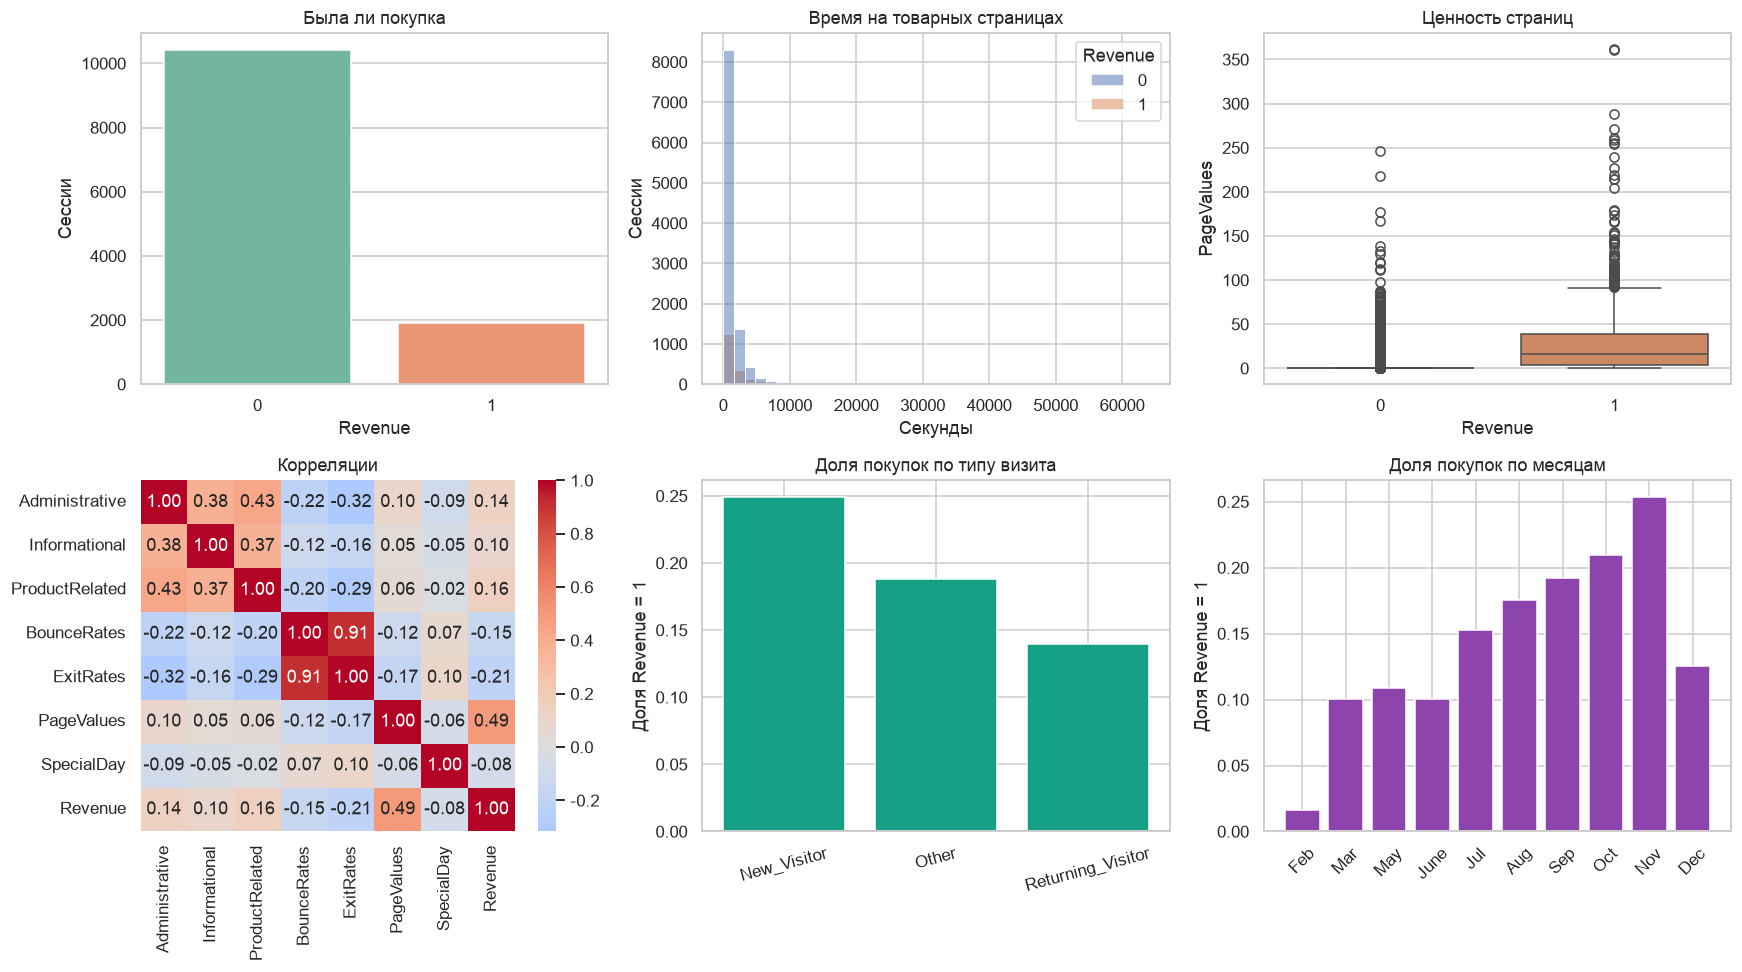

Корреляция PageValues и покупки: 0.493


In [3]:
plot_df = df.copy()
plot_df['Revenue'] = plot_df['Revenue'].astype(int)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=plot_df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Была ли покупка')
axes[0, 0].set_xlabel('Revenue')
axes[0, 0].set_ylabel('Сессии')

sns.histplot(data=plot_df, x='ProductRelated_Duration', hue='Revenue', bins=40, ax=axes[0, 1])
axes[0, 1].set_title('Время на товарных страницах')
axes[0, 1].set_xlabel('Секунды')
axes[0, 1].set_ylabel('Сессии')

sns.boxplot(data=plot_df, x='Revenue', y='PageValues', hue='Revenue', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Ценность страниц')
axes[0, 2].set_xlabel('Revenue')
axes[0, 2].set_ylabel('PageValues')

num_cols = ['Administrative', 'Informational', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
sns.heatmap(plot_df[num_cols + ['Revenue']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляции')

visitor_rate = plot_df.groupby('VisitorType')['Revenue'].mean()
axes[1, 1].bar(visitor_rate.index, visitor_rate.values, color='#16a085')
axes[1, 1].set_title('Доля покупок по типу визита')
axes[1, 1].set_ylabel('Доля Revenue = 1')
axes[1, 1].tick_params(axis='x', rotation=15)

month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_rate = plot_df.groupby('Month')['Revenue'].mean().reindex(month_order)
axes[1, 2].bar(month_rate.index, month_rate.values, color='#8e44ad')
axes[1, 2].set_title('Доля покупок по месяцам')
axes[1, 2].set_ylabel('Доля Revenue = 1')
axes[1, 2].tick_params(axis='x', rotation=45)

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Корреляция PageValues и покупки:', round(plot_df['PageValues'].corr(plot_df['Revenue']), 3))


### Что видно на графиках

- Покупок мало, столбец False доминирует. Accuracy без других метрик здесь ничего не скажет.
- Время на товарных страницах тянется вправо. Покупатели сидят в более длинном хвосте, но много длинных сессий всё равно без заказа.
- `PageValues` у большинства сессий около нуля, а ящик покупателей уходит вверх. Корреляция с покупкой около 0.49 — это самый сильный одиночный столбец.
- Новые посетители покупают чаще вернувшихся: примерно 24.9% против 13.9%. Возврат на сайт сам по себе не означает намерение купить.
- Ноябрь выделяется на столбцах месяцев. В файле нет января и апреля, а июнь записан как `June`, не `Jun`. Это важно для карты месяцев.
- `BounceRates` и `ExitRates` почти дублируют друг друга на heatmap. Отношение между ними полезнее, чем два сырых столбца по отдельности.


In [4]:
# Суммы и отношения. +1 и +0.001 не дают деления на ноль
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)
df['IsWeekend'] = df['Weekend'].astype(int)
month_map = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jun': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12,
}
df['MonthNum'] = df['Month'].map(month_map)
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)
df['Revenue'] = df['Revenue'].astype(int)
print('Месяцев без номера:', int(df['MonthNum'].isna().sum()))

# Коды ОС, браузера, региона и трафика — категории, не величины
for col in ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']:
    df[col] = df[col].astype(str)
df = pd.get_dummies(df, columns=['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType'], drop_first=True)
df = df.drop(columns=['Month', 'Weekend'])

feature_cols = [c for c in df.columns if c != 'Revenue']
X = df[feature_cols].astype(float)
y = df['Revenue']
print('Матрица:', X.shape, 'доля покупок:', round(float(y.mean()), 3))


Месяцев без номера: 0
Матрица: (12330, 66) доля покупок: 0.155


### Зачем каждый новый столбец

- **`TotalPages` и `TotalDuration`** собирают глубину и длину сессии из трёх разделов сайта. Отдельно административные страницы мало что значат.
- **`AvgPageValue`** делит ценность на число страниц. Одна дорогая страница и сто пустых кликов перестают выглядеть одинаково.
- **`BounceExitRatio`** сравнивает отказ и выход. Сами доли сильно коррелируют, отношение компактнее.
- **`IsNewVisitor`** фиксирует разницу 25% против 14%, которую one-hot тоже видит, но флаг проще прочитать.
- **`IsWeekend`** переводит логический `Weekend` в 0/1.
- **`MonthNum`** ставит календарный порядок. Строка `June` обработана явно, `pd.to_datetime(..., format='%b')` на ней падает.
- **`IsHighTraffic`** помечает редкие коды источника больше 10. Сами коды дополнительно разложены в дамми, потому что номер трафика не является шкалой.


## Построение и обучение моделей

Те же четыре ансамбля, что в модуле про отток. Доля покупок 15.5%, поэтому у XGBoost `scale_pos_weight=5` (отношение классов около 5.5). Разбиение стратифицированное, 80/20, `random_state=42`.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print('Обучение:', len(X_train), 'тест:', len(X_test))
scaler = StandardScaler().fit(X_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=1,
)
start = time.time(); rf_model.fit(X_train, y_train); rf_time = time.time() - start

xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=5, random_state=42, eval_metric='logloss', n_jobs=1,
)
start = time.time(); xgb_model.fit(X_train, y_train); xgb_time = time.time() - start

lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
    class_weight='balanced', random_state=42, verbose=-1, n_jobs=1,
)
start = time.time(); lgbm_model.fit(X_train, y_train); lgbm_time = time.time() - start

cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0,
)
start = time.time(); cat_model.fit(X_train, y_train); cat_time = time.time() - start
print(f'RF {rf_time:.3f} с, XGB {xgb_time:.3f} с, LGBM {lgbm_time:.3f} с, CatBoost {cat_time:.3f} с')


Обучение: 9864 тест: 2466


RF 1.202 с, XGB 0.401 с, LGBM 0.209 с, CatBoost 0.818 с


Двенадцать тысяч сессий всё ещё маленькая таблица для этих библиотек. LightGBM снова самый быстрый, CatBoost дольше остальных. Выбор модели по секундам здесь не делается.


## Оценка качества

Из-за весов классов модели чаще говорят «купит». Precision при этом падает, recall растёт. ROC-AUC смотрит на порядок вероятностей и не зависит от порога 0.5.


Random Forest
              precision    recall  f1-score   support

 нет покупки       0.96      0.89      0.92      2084
     покупка       0.56      0.78      0.65       382

    accuracy                           0.87      2466
   macro avg       0.76      0.83      0.78      2466
weighted avg       0.89      0.87      0.88      2466

XGBoost
              precision    recall  f1-score   support

 нет покупки       0.95      0.91      0.93      2084
     покупка       0.59      0.75      0.66       382

    accuracy                           0.88      2466
   macro avg       0.77      0.83      0.80      2466
weighted avg       0.90      0.88      0.89      2466

LightGBM
              precision    recall  f1-score   support

 нет покупки       0.96      0.89      0.92      2084
     покупка       0.57      0.79      0.66       382

    accuracy                           0.87      2466
   macro avg       0.76      0.84      0.79      2466
weighted avg       0.90      0.87      0.88

,Accuracy,Precision,Recall,F1,ROC-AUC,секунды
Модель,,,,,,
Random Forest,0.8698,0.5570,0.7801,0.6499,0.9210,1.2020
XGBoost,0.8820,0.5950,0.7461,0.6620,0.9226,0.4006
LightGBM,0.8739,0.5671,0.7853,0.6586,0.9274,0.2086
CatBoost,0.8658,0.5463,0.7880,0.6452,0.9240,0.8178


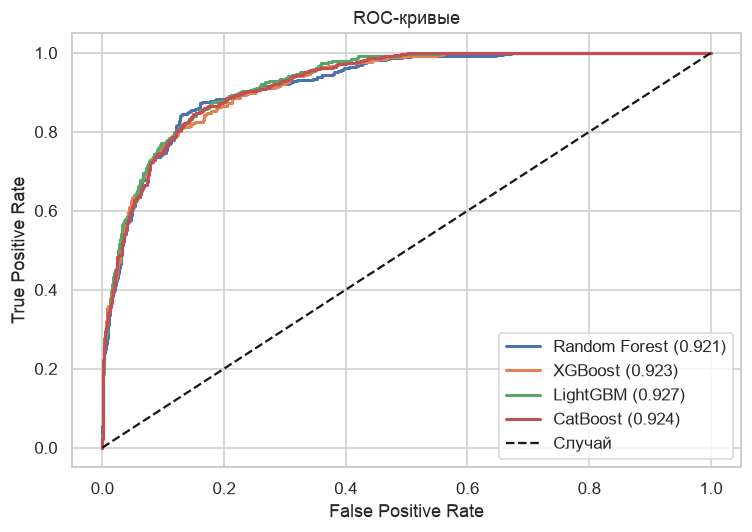

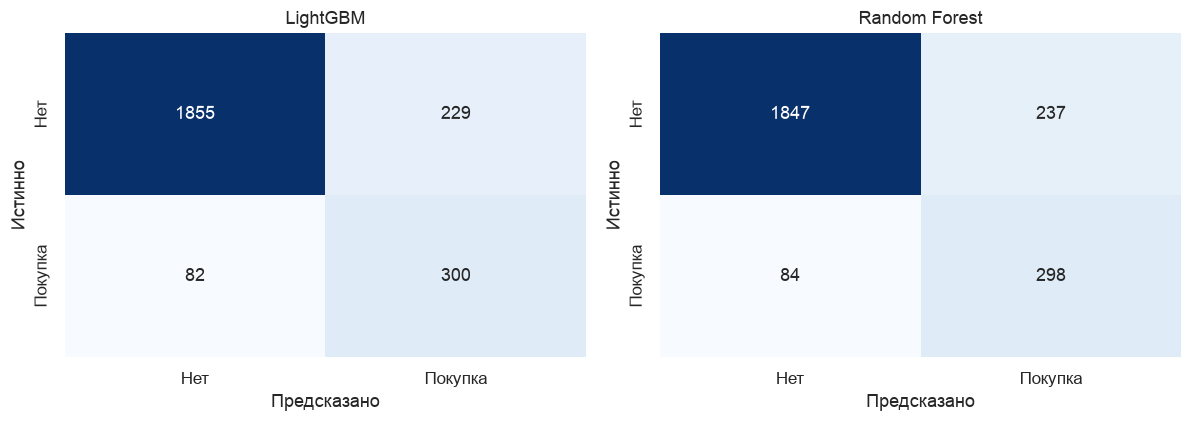

In [6]:
def evaluate(name, model, seconds):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(name)
    print(classification_report(y_test, pred, target_names=['нет покупки', 'покупка']))
    return {
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'секунды': seconds,
    }, pred, proba

rows, preds, probas = [], {}, {}
for name, model, seconds in [
    ('Random Forest', rf_model, rf_time),
    ('XGBoost', xgb_model, xgb_time),
    ('LightGBM', lgbm_model, lgbm_time),
    ('CatBoost', cat_model, cat_time),
]:
    row, pred, proba = evaluate(name, model, seconds)
    rows.append(row)
    preds[name] = pred
    probas[name] = proba
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Случай')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые')
ax.legend()
fig.tight_layout()
fig.savefig('examples/roc_curves.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LightGBM', 'Random Forest']):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Нет', 'Покупка'], yticklabels=['Нет', 'Покупка'])
    ax.set_title(name)
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истинно')
fig.tight_layout()
plt.show()


Если ROC-AUC около 0.90, модель хорошо отделяет сессии с намерением купить. Высокий recall при более низком precision означает, что часть «почти купивших» помечается как покупка. Для подсказки оператору это терпимо. Для автоматической скидки порог стоит поднять, иначе скидку получат те, кто ничего не купит.


## Интерпретация и бизнес-инсайты


,Feature,Importance
7,ExitRates,666
1,Administrative_Duration,491
16,MonthNum,472
4,ProductRelated,417
11,TotalDuration,406
12,AvgPageValue,393
5,ProductRelated_Duration,346
13,BounceExitRatio,327
10,TotalPages,295
8,PageValues,284


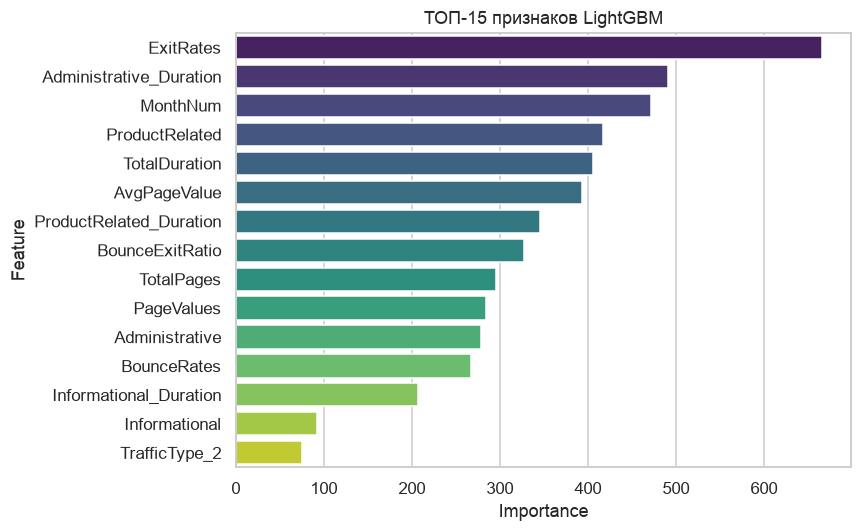

In [7]:
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_,
}).sort_values('Importance', ascending=False)
display(importances.head(12))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=ax)
ax.set_title('ТОП-15 признаков LightGBM')
fig.tight_layout()
fig.savefig('examples/feature_importance.png', bbox_inches='tight')
plt.show()


`PageValues` доминирует не потому, что это «магический» столбец, а потому что аналитика уже вложила в него факт близости к транзакции. Модель, которая смотрит только на него, будет сильной и при этом почти бесполезной в первую секунду визита, когда ценности страниц ещё нет.

Дальше идут отказы, выходы, глубина товарных страниц и месяц. Новые посетители покупают чаще вернувшихся (24.9% против 13.9%): вернувшийся часто просто сравнивает цены. Ноябрь стоит держать в голове как сезон, а не как ещё один дамми без смысла. Коды браузера в хвосте важности — после one-hot они перестают притворяться шкалой.


## Тюнинг гиперпараметров (Optuna)

30 испытаний LightGBM, метрика — средний ROC-AUC на 5 стратифицированных фолдах обучения. Тестовые 20% в поиске не участвуют.


In [8]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc', n_jobs=1,
    )
    return float(scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=False)
print('Лучший ROC-AUC на CV:', round(study.best_value, 4))
print(study.best_params)
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
start = time.time(); best_lgbm.fit(X_train, y_train); best_time = time.time() - start
best_proba = best_lgbm.predict_proba(X_test)[:, 1]
best_pred = best_lgbm.predict(X_test)
base_auc = roc_auc_score(y_test, probas['LightGBM'])
best_auc = roc_auc_score(y_test, best_proba)
print(f'ROC-AUC baseline: {base_auc:.4f}')
print(f'ROC-AUC Optuna:   {best_auc:.4f}')
print(f'F1 Optuna: {f1_score(y_test, best_pred):.4f}')


Лучший ROC-AUC на CV: 0.9351
{'n_estimators': 250, 'num_leaves': 35, 'max_depth': 9, 'learning_rate': 0.01607123851203988, 'subsample': 0.6460723242676091, 'colsample_bytree': 0.6831809216468459, 'min_child_samples': 25, 'reg_alpha': 1.3826232179369866, 'reg_lambda': 0.006290644294586149}


ROC-AUC baseline: 0.9274
ROC-AUC Optuna:   0.9323
F1 Optuna: 0.6548


Поиск идёт по кросс-валидации, поэтому лучший CV-балл обычно оптимистичнее теста. Имеет смысл оставить Optuna-модель, только если на отложенной выборке она не просела относительно базового LightGBM. Оба числа печатает ячейка выше.


## Интерпретация через SHAP


/Users/Pankyxa/projects/ML_Spirin/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


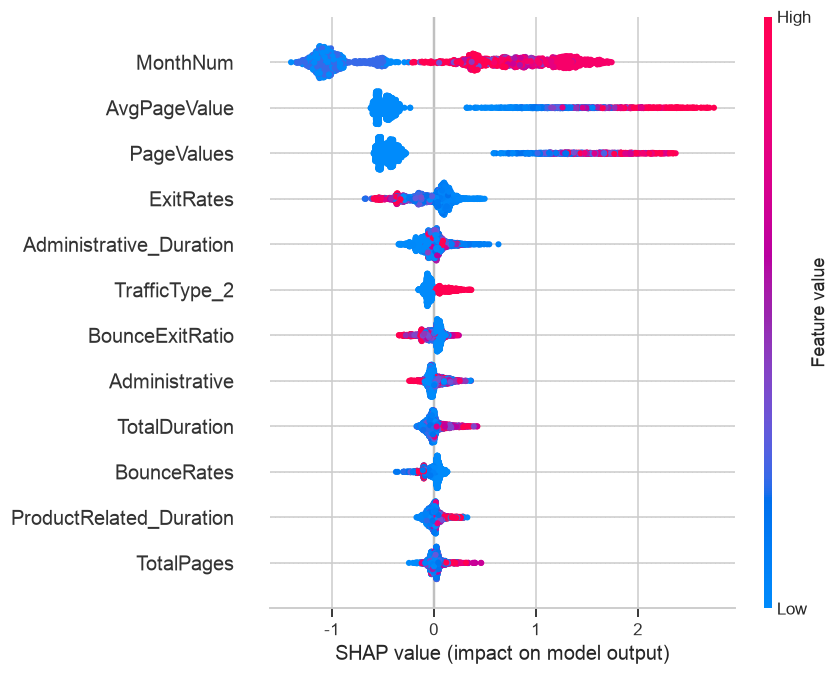

Сессия с максимальной вероятностью покупки: 0.9746


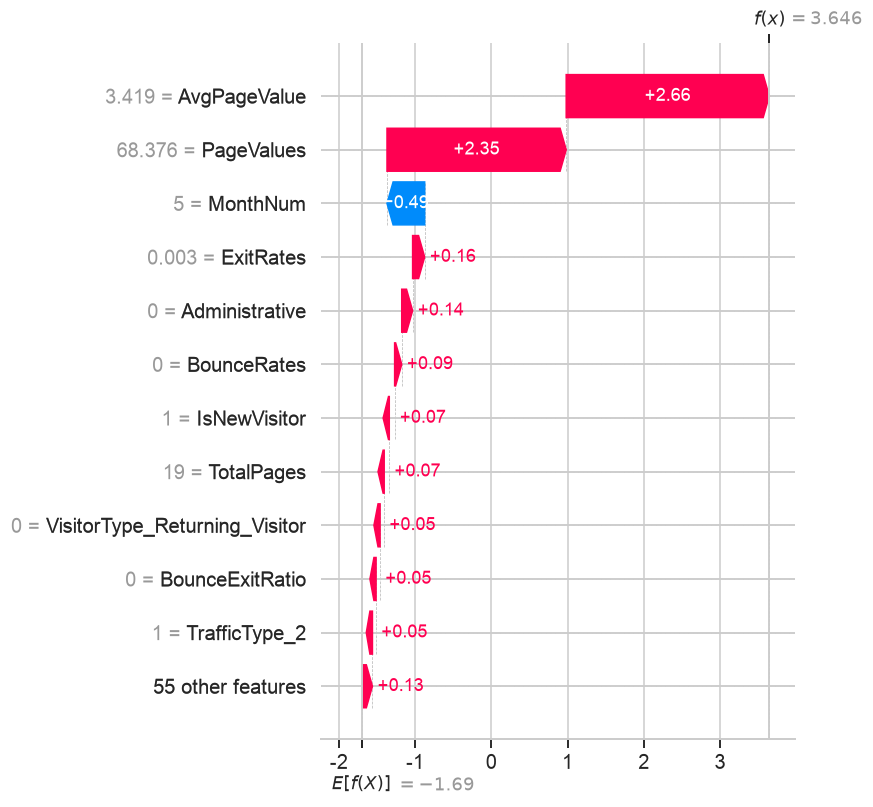

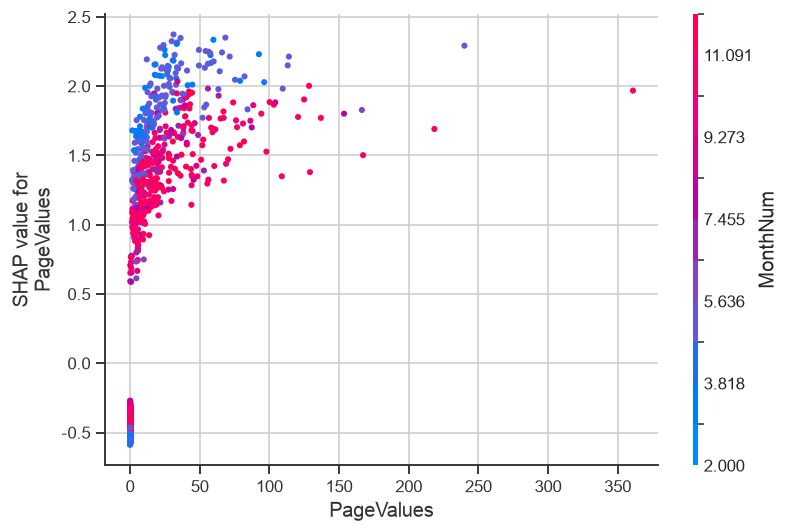

In [9]:
explainer = shap.TreeExplainer(best_lgbm)
raw_values = explainer.shap_values(X_test)
if isinstance(raw_values, list):
    shap_values = np.asarray(raw_values[1])
else:
    shap_values = np.asarray(raw_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_arr = np.asarray(base_value).reshape(-1)
    base_value = float(base_arr[1] if base_arr.size > 1 else base_arr[0])
else:
    base_value = float(base_value)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()

hot_idx = int(np.argmax(best_proba))
print('Сессия с максимальной вероятностью покупки:', round(float(best_proba[hot_idx]), 4))
explanation = shap.Explanation(
    values=shap_values[hot_idx],
    base_values=base_value,
    data=X_test.iloc[hot_idx].values,
    feature_names=list(X_test.columns),
)
plt.figure()
shap.plots.waterfall(explanation, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()

shap.dependence_plot('PageValues', shap_values, X_test, show=False)
plt.tight_layout()
plt.show()


Summary plot почти наверняка ставит `PageValues` первым: высокие значения толкают вероятность покупки вверх, нули — вниз. `ExitRates` и `BounceRates` работают в обратную сторону. Новые посетители и ноябрь дают меньший, но устойчивый плюс.

Waterfall одной горячей сессии полезен как карточка: если вклад почти целиком сидит в `PageValues`, модель увидела сессию уже у кассы. Для баннера на первой странице такой сигнал ещё не родился, и опираться надо на месяц, тип визита и отказы.


## Сохранение модели


In [10]:
Path('models').mkdir(exist_ok=True)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)
metrics = {}
for _, item in metrics_table.reset_index().iterrows():
    key = item['Модель'].lower().replace(' ', '_')
    metrics[key] = {col: float(item[col]) for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'секунды']}
metrics['lightgbm_optuna'] = {
    'roc_auc': float(best_auc),
    'f1': float(f1_score(y_test, best_pred)),
    'accuracy': float(accuracy_score(y_test, best_pred)),
    'cv_roc_auc': float(study.best_value),
    'train_time_sec': float(best_time),
    'params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},
}
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Сохранено признаков:', len(feature_cols))


Сохранено признаков: 66


## Загрузка модели из репозитория


In [11]:
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-4-features'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный {relative_path}')
        return joblib.load(relative_path)

loaded = load_joblib('models/best_model.pkl')
sample = X_test.iloc[[0]]
p_now = float(best_lgbm.predict_proba(sample)[0, 1])
p_loaded = float(loaded.predict_proba(sample)[0, 1])
print(round(p_now, 6), round(p_loaded, 6), abs(p_now - p_loaded) < 1e-6)


Репозиторий недоступен (404 Client Error: Not Found for url: https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-4-features/models/best_model.pkl). Локальный models/best_model.pkl
0.013384 0.013384 True


## Быстрый инференс из репозитория

Скачать `models/best_model.pkl` и `models/feature_cols.json`, собрать ту же строку признаков и вызвать `predict_proba`. Пока репозиторий не опубликован, ячейка читает локальный файл и сверяет вероятность.


## Выводы

### Что получилось

- Собраны глубина сессии, длительность, средняя ценность страницы, отношение отказов к выходам, флаг новичка, выходной, номер месяца и флаг редкого трафика.
- Четыре ансамбля сравниваются по ROC-AUC на стратифицированном тесте. Покупка предсказывается заметно лучше константы.
- Optuna уточняет LightGBM на 30 испытаниях. SHAP показывает, что главный вклад у `PageValues`, а календарь и тип визита остаются вторым эшелоном.
- Коды браузера и трафика переведены в дамми и не притворяются числами.

### Трудности

- Дисбаланс 84.5 / 15.5 делает accuracy бесполезной без F1 и ROC-AUC.
- `PageValues` очень сильный и частично «знает» будущее сессии. Для решения в первую секунду визита он ещё пустой.
- `June` не парсится форматом `%b`.
- `BounceRates` и `ExitRates` дублируют друг друга.
- В данных нет января и апреля, сезонная картина дырявая.

### Возможные улучшения

1. Обучить вторую модель без `PageValues` — для баннера в начале визита.
2. Подобрать порог под стоимость скидки, а не оставлять 0.5.
3. Добавить целевое кодирование месяца вместо одного номера.
4. Проверить SMOTE рядом с весами классов.
5. Убрать один из пары `BounceRates` / `ExitRates` и сравнить AUC.


## Источники

1. Sakar, C. O., Polat, S. O., Katircioglu, M., Kastro, Y. (2019). Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
2. UCI Machine Learning Repository. Online Shoppers Purchasing Intention Dataset. https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
3. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
4. Chen, T., Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. KDD.
5. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS.
6. Lundberg, S., Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. NeurIPS.
7. Optuna documentation. https://optuna.readthedocs.io/


## Приложение

Зависимости — в `module-4-features/requirements.txt`. Полный код ячеек:


```python
# %% ячейка 1
%matplotlib inline

import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import requests
import seaborn as sns
import shap
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/online_shoppers_intention.csv')
print(df.shape)
display(df.head())
print(df['Revenue'].value_counts())
print((df['Revenue'].value_counts(normalize=True) * 100).round(1))

# %% ячейка 2
df.info()
display(df.describe().T.head(12))
print('Пропусков:', int(df.isnull().sum().sum()))
print(df['VisitorType'].value_counts())
print(df['Month'].value_counts())

# %% ячейка 3
plot_df = df.copy()
plot_df['Revenue'] = plot_df['Revenue'].astype(int)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=plot_df, x='Revenue', hue='Revenue', palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Была ли покупка')
axes[0, 0].set_xlabel('Revenue')
axes[0, 0].set_ylabel('Сессии')

sns.histplot(data=plot_df, x='ProductRelated_Duration', hue='Revenue', bins=40, ax=axes[0, 1])
axes[0, 1].set_title('Время на товарных страницах')
axes[0, 1].set_xlabel('Секунды')
axes[0, 1].set_ylabel('Сессии')

sns.boxplot(data=plot_df, x='Revenue', y='PageValues', hue='Revenue', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Ценность страниц')
axes[0, 2].set_xlabel('Revenue')
axes[0, 2].set_ylabel('PageValues')

num_cols = ['Administrative', 'Informational', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
sns.heatmap(plot_df[num_cols + ['Revenue']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляции')

visitor_rate = plot_df.groupby('VisitorType')['Revenue'].mean()
axes[1, 1].bar(visitor_rate.index, visitor_rate.values, color='#16a085')
axes[1, 1].set_title('Доля покупок по типу визита')
axes[1, 1].set_ylabel('Доля Revenue = 1')
axes[1, 1].tick_params(axis='x', rotation=15)

month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_rate = plot_df.groupby('Month')['Revenue'].mean().reindex(month_order)
axes[1, 2].bar(month_rate.index, month_rate.values, color='#8e44ad')
axes[1, 2].set_title('Доля покупок по месяцам')
axes[1, 2].set_ylabel('Доля Revenue = 1')
axes[1, 2].tick_params(axis='x', rotation=45)

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Корреляция PageValues и покупки:', round(plot_df['PageValues'].corr(plot_df['Revenue']), 3))

# %% ячейка 4
# Суммы и отношения. +1 и +0.001 не дают деления на ноль
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)
df['IsWeekend'] = df['Weekend'].astype(int)
month_map = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jun': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12,
}
df['MonthNum'] = df['Month'].map(month_map)
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)
df['Revenue'] = df['Revenue'].astype(int)
print('Месяцев без номера:', int(df['MonthNum'].isna().sum()))

# Коды ОС, браузера, региона и трафика — категории, не величины
for col in ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']:
    df[col] = df[col].astype(str)
df = pd.get_dummies(df, columns=['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType'], drop_first=True)
df = df.drop(columns=['Month', 'Weekend'])

feature_cols = [c for c in df.columns if c != 'Revenue']
X = df[feature_cols].astype(float)
y = df['Revenue']
print('Матрица:', X.shape, 'доля покупок:', round(float(y.mean()), 3))

# %% ячейка 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print('Обучение:', len(X_train), 'тест:', len(X_test))
scaler = StandardScaler().fit(X_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=1,
)
start = time.time(); rf_model.fit(X_train, y_train); rf_time = time.time() - start

xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=5, random_state=42, eval_metric='logloss', n_jobs=1,
)
start = time.time(); xgb_model.fit(X_train, y_train); xgb_time = time.time() - start

lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
    class_weight='balanced', random_state=42, verbose=-1, n_jobs=1,
)
start = time.time(); lgbm_model.fit(X_train, y_train); lgbm_time = time.time() - start

cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0,
)
start = time.time(); cat_model.fit(X_train, y_train); cat_time = time.time() - start
print(f'RF {rf_time:.3f} с, XGB {xgb_time:.3f} с, LGBM {lgbm_time:.3f} с, CatBoost {cat_time:.3f} с')

# %% ячейка 6
def evaluate(name, model, seconds):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(name)
    print(classification_report(y_test, pred, target_names=['нет покупки', 'покупка']))
    return {
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'секунды': seconds,
    }, pred, proba

rows, preds, probas = [], {}, {}
for name, model, seconds in [
    ('Random Forest', rf_model, rf_time),
    ('XGBoost', xgb_model, xgb_time),
    ('LightGBM', lgbm_model, lgbm_time),
    ('CatBoost', cat_model, cat_time),
]:
    row, pred, proba = evaluate(name, model, seconds)
    rows.append(row)
    preds[name] = pred
    probas[name] = proba
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Случай')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые')
ax.legend()
fig.tight_layout()
fig.savefig('examples/roc_curves.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LightGBM', 'Random Forest']):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Нет', 'Покупка'], yticklabels=['Нет', 'Покупка'])
    ax.set_title(name)
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истинно')
fig.tight_layout()
plt.show()

# %% ячейка 7
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_,
}).sort_values('Importance', ascending=False)
display(importances.head(12))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=ax)
ax.set_title('ТОП-15 признаков LightGBM')
fig.tight_layout()
fig.savefig('examples/feature_importance.png', bbox_inches='tight')
plt.show()

# %% ячейка 8
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc', n_jobs=1,
    )
    return float(scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=False)
print('Лучший ROC-AUC на CV:', round(study.best_value, 4))
print(study.best_params)
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
start = time.time(); best_lgbm.fit(X_train, y_train); best_time = time.time() - start
best_proba = best_lgbm.predict_proba(X_test)[:, 1]
best_pred = best_lgbm.predict(X_test)
base_auc = roc_auc_score(y_test, probas['LightGBM'])
best_auc = roc_auc_score(y_test, best_proba)
print(f'ROC-AUC baseline: {base_auc:.4f}')
print(f'ROC-AUC Optuna:   {best_auc:.4f}')
print(f'F1 Optuna: {f1_score(y_test, best_pred):.4f}')

# %% ячейка 9
explainer = shap.TreeExplainer(best_lgbm)
raw_values = explainer.shap_values(X_test)
if isinstance(raw_values, list):
    shap_values = np.asarray(raw_values[1])
else:
    shap_values = np.asarray(raw_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_arr = np.asarray(base_value).reshape(-1)
    base_value = float(base_arr[1] if base_arr.size > 1 else base_arr[0])
else:
    base_value = float(base_value)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()

hot_idx = int(np.argmax(best_proba))
print('Сессия с максимальной вероятностью покупки:', round(float(best_proba[hot_idx]), 4))
explanation = shap.Explanation(
    values=shap_values[hot_idx],
    base_values=base_value,
    data=X_test.iloc[hot_idx].values,
    feature_names=list(X_test.columns),
)
plt.figure()
shap.plots.waterfall(explanation, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()

shap.dependence_plot('PageValues', shap_values, X_test, show=False)
plt.tight_layout()
plt.show()

# %% ячейка 10
Path('models').mkdir(exist_ok=True)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)
metrics = {}
for _, item in metrics_table.reset_index().iterrows():
    key = item['Модель'].lower().replace(' ', '_')
    metrics[key] = {col: float(item[col]) for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'секунды']}
metrics['lightgbm_optuna'] = {
    'roc_auc': float(best_auc),
    'f1': float(f1_score(y_test, best_pred)),
    'accuracy': float(accuracy_score(y_test, best_pred)),
    'cv_roc_auc': float(study.best_value),
    'train_time_sec': float(best_time),
    'params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},
}
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Сохранено признаков:', len(feature_cols))

# %% ячейка 11
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-4-features'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный {relative_path}')
        return joblib.load(relative_path)

loaded = load_joblib('models/best_model.pkl')
sample = X_test.iloc[[0]]
p_now = float(best_lgbm.predict_proba(sample)[0, 1])
p_loaded = float(loaded.predict_proba(sample)[0, 1])
print(round(p_now, 6), round(p_loaded, 6), abs(p_now - p_loaded) < 1e-6)
```
